# 02: YouTube performance analysis

This notebook answers five questions with **SQL queries and Python charts**:

1. Does upload day or hour relate to performance?
2. Do shorter or longer videos perform better?
3. Do title characteristics relate to performance?
4. How do engagement ratios differ between channels?
5. Which videos are breakouts compared with their own channel?

## Rules used throughout

- Use only `in_analysis = 1`: published, non-live videos at least 30 days old.
- Use only rows with a `performance_index`: at least five similar videos exist for a stable median.
- `performance_index = this video's views per day / the median views per day for the same channel, format and age group`.
  `1.0` means typical; `2.0` means twice typical.
- Use medians, not means. A viral video can distort a mean.
- Results show **correlation, not causation**. Upload time, topic, channel, promotion and season can overlap.

The SQL lives in `sql/analysis.sql`, so the notebook and later dashboard can reuse the same tested queries.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display, Markdown

# This notebook runs with notebooks/ as its working folder.
sys.path.insert(0, str(Path.cwd().parent / "src"))
from config import FIGURES_DIR
from db import connect, load_queries

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

conn = connect()
queries = load_queries()
features = pd.read_sql(
    "SELECT * FROM video_features WHERE in_analysis = 1 AND performance_index IS NOT NULL",
    conn,
)

def run(name):
    """Run a named SQL query and display its result."""
    result = pd.read_sql(queries[name], conn)
    print(f"SQL: {name} | {len(result):,} rows")
    display(result)
    return result

print(f"Analyzed rows: {len(features):,}")
print(f"Channels: {features['channel_name'].nunique()}")
print(f"Collection snapshot: {features['snapshot_id'].iloc[0]}")

Analyzed rows: 2,724
Channels: 15
Collection snapshot: 2026-10-19_230140


## 1. Upload timing

The API timestamps are UTC. `src/features.py` converted them to `Asia/Jakarta` before creating `publish_dow` and `publish_hour`.

Use 4-hour blocks instead of single hours: some individual hours contain only 9 videos. The fair comparison is the median `performance_index`, not raw views.

In [2]:
weekday = run("by_weekday")
hours = run("by_hour_block")
uploaders = run("top_uploader_per_hour_block")

SQL: by_weekday | 7 rows


,weekday,videos,median_views_per_day,median_performance_index
0,Monday,233,1329.0,1.01
1,Tuesday,419,1555.0,1.00
2,Wednesday,486,1305.0,1.00
3,Thursday,512,1706.0,1.00
4,Friday,422,1498.0,1.00
5,Saturday,360,1807.0,1.00
6,Sunday,292,1298.0,0.98


SQL: by_hour_block | 6 rows


,hour_block,videos,median_views_per_day,median_performance_index
0,00-03,838,1660.0,1.00
1,04-07,379,867.0,0.98
2,08-11,82,962.0,1.20
3,12-15,57,1104.0,1.24
4,16-19,239,4316.0,1.12
5,20-23,1129,1432.0,0.99


SQL: top_uploader_per_hour_block | 6 rows


,hour_block,videos,top_channel,top_channel_videos,top_channel_share_pct
0,00-03,838,ShortCircuit,115,14.0
1,04-07,379,UrAvgConsumer,70,18.0
2,08-11,82,iJustine,19,23.0
3,12-15,57,Dave2D,13,23.0
4,16-19,239,Mrwhosetheboss,83,35.0
5,20-23,1129,JerryRigEverything,139,12.0


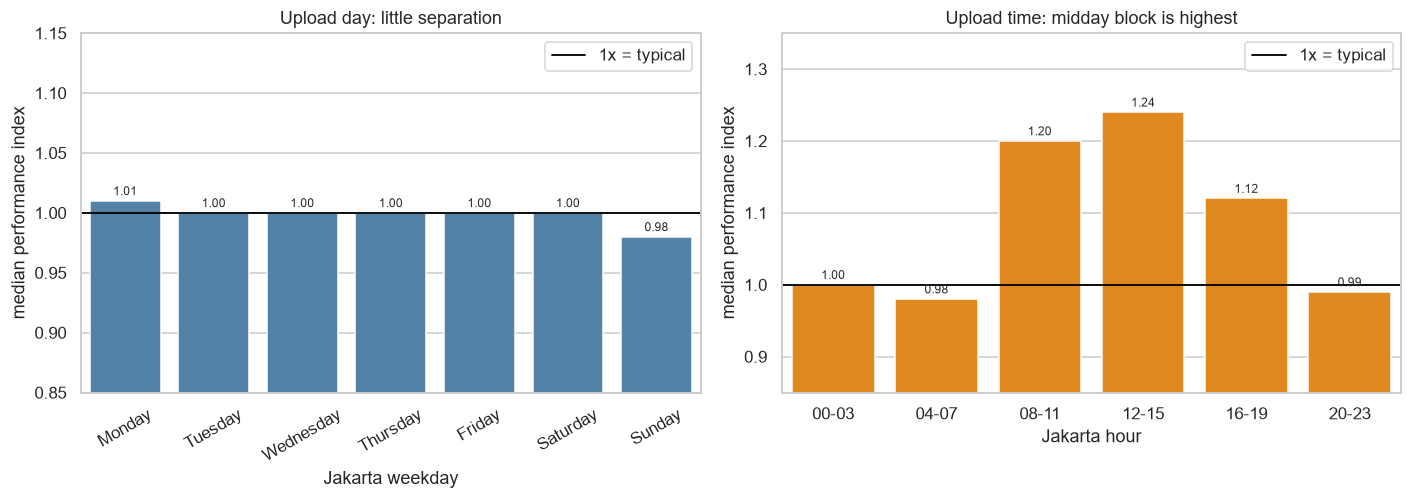

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.7))

sns.barplot(data=weekday, x="weekday", y="median_performance_index", color="steelblue", ax=axes[0])
axes[0].axhline(1, color="black", linewidth=1.2, label="1x = typical")
axes[0].set(title="Upload day: little separation", xlabel="Jakarta weekday", ylabel="median performance index")
axes[0].tick_params(axis="x", rotation=30)
axes[0].set_ylim(0.85, 1.15)
axes[0].legend()

sns.barplot(data=hours, x="hour_block", y="median_performance_index", color="darkorange", ax=axes[1])
axes[1].axhline(1, color="black", linewidth=1.2, label="1x = typical")
axes[1].set(title="Upload time: midday block is highest", xlabel="Jakarta hour", ylabel="median performance index")
axes[1].set_ylim(0.85, 1.35)
axes[1].legend()
for ax in axes:
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", padding=2, fontsize=8)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "05_upload_timing.png", dpi=140, bbox_inches="tight")
plt.show()

### Timing finding

- **Day:** all weekday medians are near `1.0` (`0.98–1.01`). This sample does not show a meaningful day-of-week relationship after normalizing by channel, format and age.
- **Hour:** `12:00–15:59` has the highest median (`1.24`, 57 videos), followed by `16:00–19:59` (`1.12`, 239 videos). `04:00–07:59` is lowest (`0.98`, 379 videos).
- **Confounding:** `Mrwhosetheboss` supplies 35% of videos in the `16:00–19:59` block, so hour is not independent of channel. Treat this as a pattern worth testing, not a recommended upload schedule.

**Conclusion:** upload day looks weak. Hour has a possible association, but channel scheduling makes a causal claim unsafe.

## 2. Video length

First compare four duration buckets. Then compare Shorts and long videos **inside each channel**, using videos 90–365 days old so both formats have the same age range.

In [4]:
duration = run("by_duration")
format_by_channel = run("shorts_vs_long_by_channel")
print("Channels where Shorts have higher median views/day:",
      int((format_by_channel["short_to_long_ratio"] > 1).sum()),
      "of", len(format_by_channel))

SQL: by_duration | 4 rows


,duration_bucket,videos,channels,median_views_per_day,median_views_per_subscriber,median_performance_index
0,short (<=3 min),1167,13,1401.0,0.041,1.00
1,3-10 min,535,15,1043.0,0.107,0.94
2,10-20 min,850,15,1740.0,0.105,1.02
3,20+ min,172,15,8470.0,0.143,1.14


SQL: shorts_vs_long_by_channel | 13 rows


,channel_name,subscribers,shorts,long_videos,short_median_views_per_day,long_median_views_per_day,short_to_long_ratio
0,UrAvgConsumer,3450000,66,43,71.0,1212.0,0.06
1,Max Tech,1270000,13,107,51.0,609.0,0.08
2,Austin Evans,5850000,85,25,665.0,3591.0,0.19
3,ZONEofTECH,1670000,65,63,153.0,560.0,0.27
4,SuperSaf,2260000,35,22,376.0,1205.0,0.31
5,The Tech Chap,1650000,45,50,428.0,886.0,0.48
6,JerryRigEverything,10100000,76,51,3121.0,5250.0,0.59
7,ShortCircuit,2550000,35,107,817.0,1042.0,0.78
8,Unbox Therapy,25600000,67,38,5655.0,5429.0,1.04
9,iJustine,7060000,103,28,206.0,196.0,1.05


Channels where Shorts have higher median views/day: 5 of 13


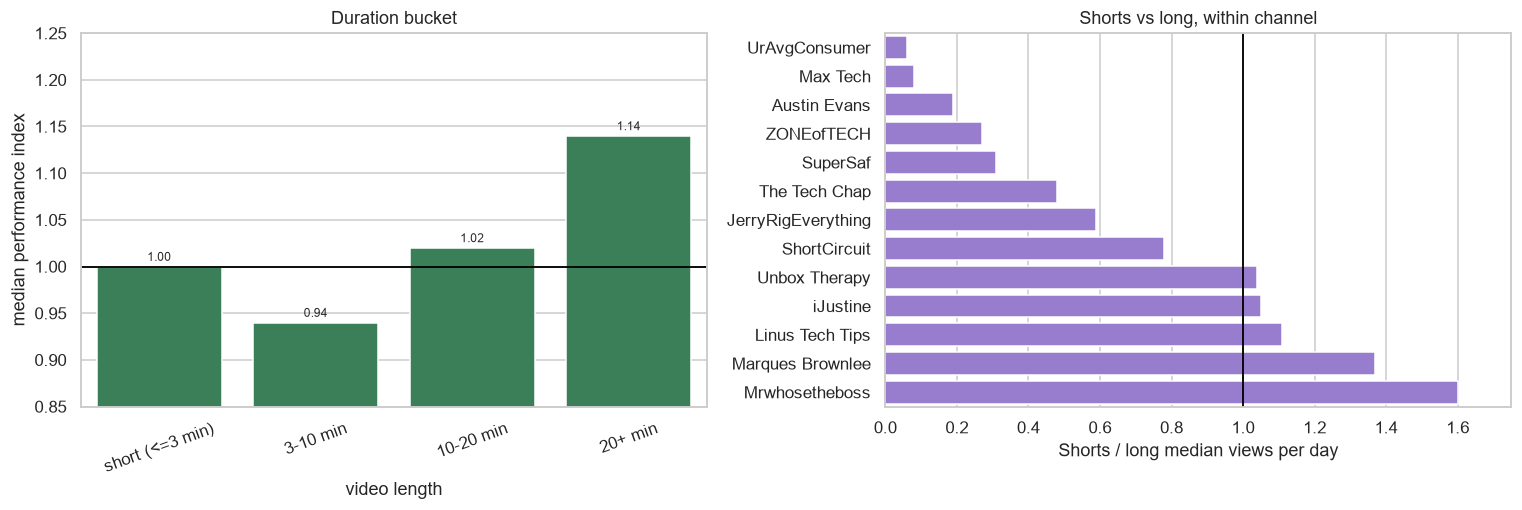

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

sns.barplot(data=duration, x="duration_bucket", y="median_performance_index", color="seagreen", ax=axes[0])
axes[0].axhline(1, color="black", linewidth=1.2)
axes[0].set(title="Duration bucket", xlabel="video length", ylabel="median performance index")
axes[0].tick_params(axis="x", rotation=20)
axes[0].set_ylim(0.85, 1.25)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.2f", padding=2, fontsize=8)

plot_data = format_by_channel.sort_values("short_to_long_ratio")
sns.barplot(data=plot_data, y="channel_name", x="short_to_long_ratio", color="mediumpurple", ax=axes[1])
axes[1].axvline(1, color="black", linewidth=1.2)
axes[1].set(title="Shorts vs long, within channel", xlabel="Shorts / long median views per day", ylabel="")
axes[1].set_xlim(0, max(1.75, plot_data.short_to_long_ratio.max() + 0.1))
plt.tight_layout()
fig.savefig(FIGURES_DIR / "06_video_length.png", dpi=140, bbox_inches="tight")
plt.show()

### Length finding

- The `20+ min` bucket has the highest fair index (`1.14`), `10–20 min` is close to typical (`1.02`), and `3–10 min` is slightly below (`0.94`).
- In the age-matched, within-channel comparison, Shorts perform better in only the channels with ratio above `1.0`; the notebook prints the exact count. Several channels strongly favor long videos.
- Raw views per day cannot answer this alone: format mix differs by channel, and Shorts view counting changed on **March 31, 2025**. YouTube began counting each Short start or replay as a view; the older metric remains “engaged views.” Source: [TechCrunch, 2025-03-26](https://techcrunch.com/2025/03/26/youtube-is-changing-how-youtube-shorts-views-are-counted/).

**Conclusion:** this dataset does not support “shorter is always better.” Long videos, especially 20+ minutes, are stronger in the fair index, but format and channel strategy are entangled.

## 3. Title characteristics

Test binary title features first. Raw views per day are shown beside the fair index to expose channel-size mix. Then inspect topic words; topic matches are rough text searches, not a sentiment or causal model.

In [6]:
title_features = run("title_features")
title_length = run("title_length")
title_style = run("title_style_by_channel")
topic_rows = run("title_topic_videos")

topics = (topic_rows.groupby("topic")
          .agg(videos=("title", "size"), channels=("channel_name", "nunique"),
               median_performance_index=("performance_index", "median"),
               pct_breakouts=("performance_index", lambda s: 100 * (s >= 3).mean()))
          .query("videos >= 25")
          .sort_values("median_performance_index", ascending=False)
          .reset_index())
topics["median_performance_index"] = topics["median_performance_index"].round(2)
topics["pct_breakouts"] = topics["pct_breakouts"].round(1)
print("Topic summary:")
display(topics)

SQL: title_features | 6 rows


,feature,in_title,videos,median_views_per_day,median_performance_index
0,has a number,yes,1341,1103.0,1.01
1,has a number,no,1383,2415.0,0.99
2,has a question mark,yes,366,1581.0,1.00
3,has a question mark,no,2358,1513.0,1.00
4,has an ALL-CAPS word,yes,910,1063.0,1.02
5,has an ALL-CAPS word,no,1814,1886.0,0.99


SQL: title_length | 4 rows


,title_length_chars,videos,median_performance_index
0,up to 30,709,1.00
1,31-45,1162,1.00
2,46-60,592,1.00
3,61+,261,0.97


SQL: title_style_by_channel | 15 rows


,channel_name,subscribers,median_views_per_day,pct_titles_with_number,pct_titles_with_caps,pct_titles_with_question
0,iJustine,7060000,331.0,30.0,16.0,12.0
1,Hardware Canucks,1920000,355.0,51.0,43.0,10.0
2,UrAvgConsumer,3450000,366.0,63.0,22.0,16.0
3,ZONEofTECH,1670000,445.0,65.0,76.0,13.0
4,Max Tech,1270000,732.0,69.0,90.0,6.0
5,The Tech Chap,1650000,752.0,69.0,42.0,27.0
6,SuperSaf,2260000,789.0,93.0,12.0,20.0
7,Dave2D,3690000,804.0,53.0,31.0,7.0
8,ShortCircuit,2550000,1280.0,58.0,19.0,11.0
9,Austin Evans,5850000,1507.0,25.0,37.0,21.0


SQL: title_topic_videos | 1,671 rows


,topic,channel_name,title,performance_index
0,"""vs"" comparison",Mrwhosetheboss,$1000 RC Cars vs Boats,48.991
1,"""vs"" comparison",Max Tech,Sony 1000x Collexion Headphones vs AirPods Max,37.408
2,"""vs"" comparison",SuperSaf,Google Pixel 10 Pro XL vs Samsung Galaxy S25 U...,13.109
3,"""vs"" comparison",Mrwhosetheboss,"$10 vs $1,000 Air Purifier",11.896
4,"""vs"" comparison",SuperSaf,Galaxy S26 Ultra vs OPPO Find X9 Ultra vs Vivo...,8.753
...,...,...,...,...
1666,iPhone,iJustine,POV: Your first iPhone still works!!,0.235
1667,iPhone,Austin Evans,Is an iPhone Kill Switch Coming?,0.221
1668,iPhone,SuperSaf,iPhone 16e Review - Worth it?,0.204
1669,iPhone,JerryRigEverything,The iPhone 17 Pro is cooler on the inside than...,0.189


Topic summary:


,topic,videos,channels,median_performance_index,pct_breakouts
0,iPhone,295,15,1.68,26.1
1,iPad,29,11,1.31,6.9
2,MacBook,116,13,1.26,14.7
3,"""vs"" comparison",167,15,1.24,18.6
4,Review,170,11,1.14,8.2
5,Apple,222,15,1.09,13.5
6,Unboxing,136,11,1.05,12.5
7,Laptop,138,14,1.05,8.0
8,Samsung,183,12,1.00,10.4
9,Fold / foldable,137,15,0.95,8.8


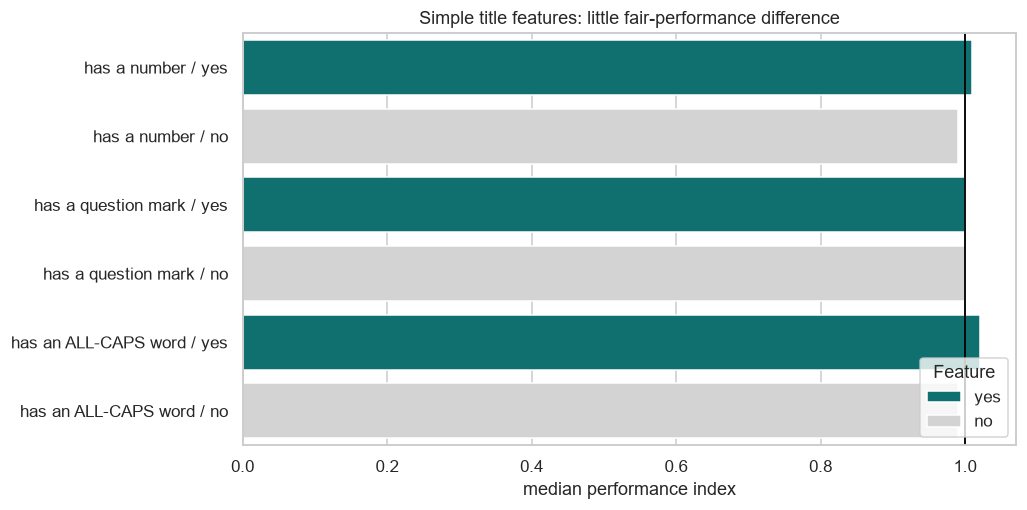

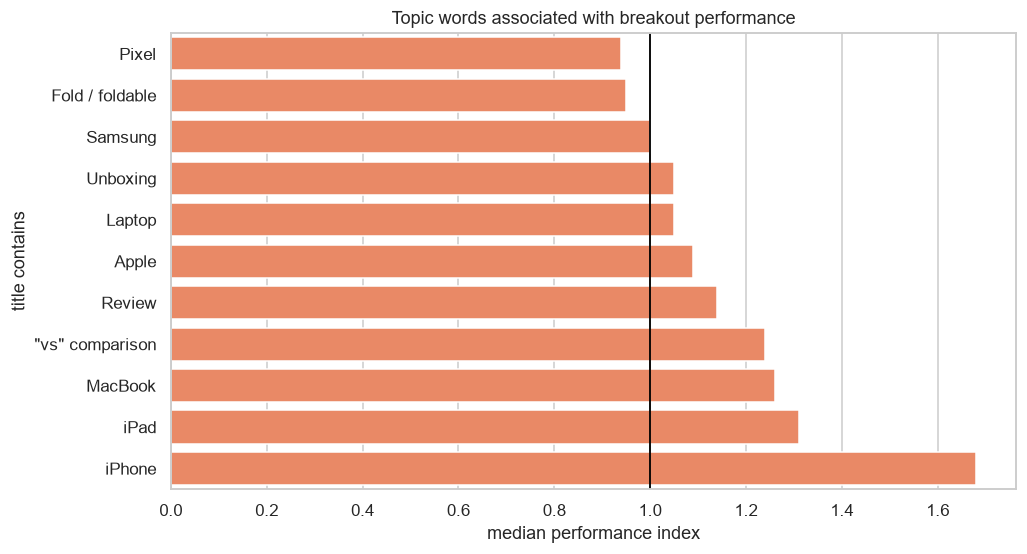

In [7]:
plot_features = title_features.copy()
plot_features["label"] = plot_features["feature"] + " / " + plot_features["in_title"]
fig, ax = plt.subplots(figsize=(9.5, 4.8))
sns.barplot(data=plot_features, y="label", x="median_performance_index", hue="in_title", dodge=False, palette={"yes": "teal", "no": "lightgray"}, ax=ax)
ax.axvline(1, color="black", linewidth=1.2)
ax.set(title="Simple title features: little fair-performance difference", xlabel="median performance index", ylabel="")
ax.legend(title="Feature", loc="lower right")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "07_title_features.png", dpi=140, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9.5, 5.2))
top_plot = topics.sort_values("median_performance_index")
sns.barplot(data=top_plot, y="topic", x="median_performance_index", color="coral", ax=ax)
ax.axvline(1, color="black", linewidth=1.2)
ax.set(title="Topic words associated with breakout performance", xlabel="median performance index", ylabel="title contains")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "08_title_topics.png", dpi=140, bbox_inches="tight")
plt.show()

### Title finding

- A question mark has no visible difference: `1.00` with or without one.
- A number (`1.01`) and an all-caps word (`1.02`) are near typical. Their raw views differ because different channels use those styles; fair normalization removes most of that difference.
- Topic is more informative than punctuation in this sample. Titles containing `iPhone` have median index `1.68`; `MacBook` is `1.26`; `Pixel` is `0.94`. This likely reflects launch timing, audience demand and channel selection, not a guaranteed title formula.

**Conclusion:** no simple title trick wins across channels. Product topic and timing show stronger associations than punctuation, but topic is also a proxy for news cycles and launches.

## 4. Engagement by channel

Likes and comments measure different behavior. Keep them as ratios because large channels naturally collect more total interactions. Keep Shorts and long videos separate because Shorts have a different viewing pattern.

In [8]:
engagement_format = run("engagement_by_format")
engagement_channel = run("engagement_by_channel")

SQL: engagement_by_format | 2 rows


,format,videos,likes_per_100_views,comments_per_1000_views,views_per_subscriber
0,long,1557,2.45,1.76,0.107
1,short,1167,2.47,0.55,0.041


SQL: engagement_by_channel | 15 rows


,channel_name,subscribers,long_likes_per_100,short_likes_per_100,long_comments_per_1000,short_comments_per_1000,long_views_per_subscriber
0,iJustine,7060000,3.44,2.71,2.13,0.74,0.009
1,Linus Tech Tips,16900000,3.13,2.30,1.72,0.32,0.074
2,JerryRigEverything,10100000,3.13,3.41,1.62,0.74,0.116
3,Dave2D,3690000,3.04,NaN,2.08,NaN,0.202
4,ShortCircuit,2550000,2.90,1.59,2.19,0.65,0.077
5,Marques Brownlee,21400000,2.59,3.46,1.43,0.57,0.222
6,Hardware Canucks,1920000,2.48,NaN,3.05,NaN,0.057
7,Austin Evans,5850000,2.46,3.59,1.19,1.47,0.088
8,Mrwhosetheboss,23000000,2.34,3.14,1.11,0.18,0.246
9,Max Tech,1270000,1.99,1.44,2.19,0.58,0.090


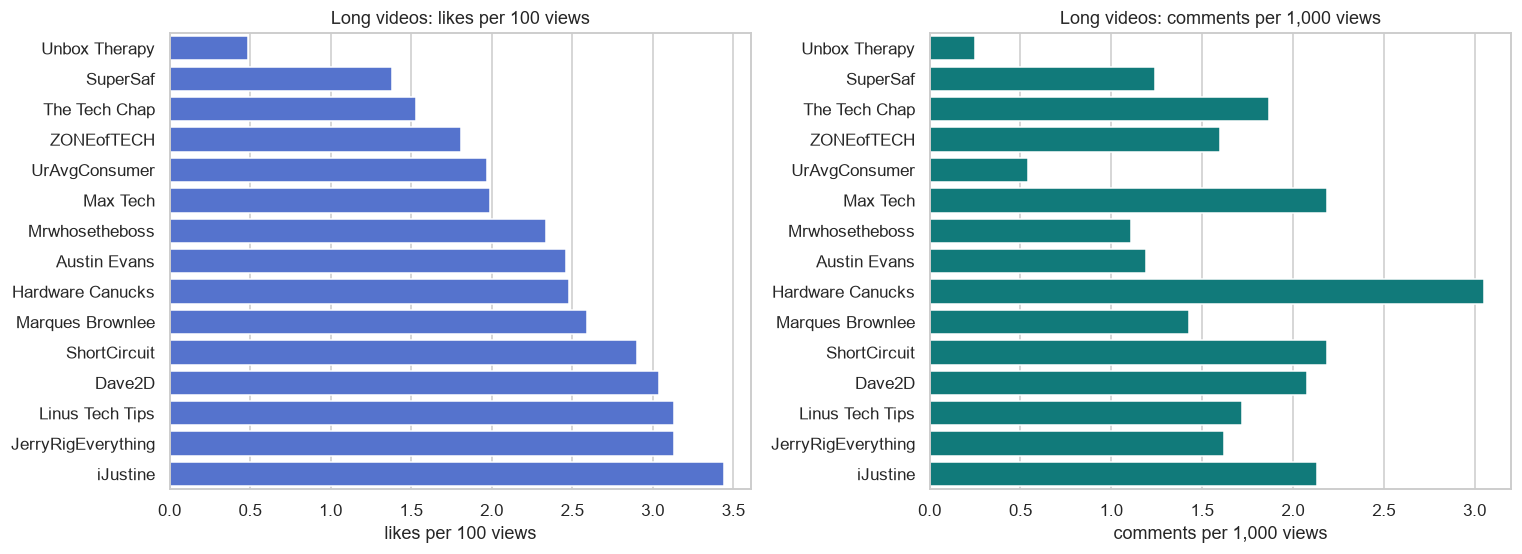

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

eng_plot = engagement_channel.sort_values("long_likes_per_100")
sns.barplot(data=eng_plot, y="channel_name", x="long_likes_per_100", color="royalblue", ax=axes[0])
axes[0].set(title="Long videos: likes per 100 views", xlabel="likes per 100 views", ylabel="")

sns.barplot(data=eng_plot, y="channel_name", x="long_comments_per_1000", color="darkcyan", ax=axes[1])
axes[1].set(title="Long videos: comments per 1,000 views", xlabel="comments per 1,000 views", ylabel="")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "09_engagement_by_channel.png", dpi=140, bbox_inches="tight")
plt.show()

### Engagement finding

- Median likes are nearly equal: `2.45` per 100 views for long videos and `2.47` for Shorts.
- Comments differ sharply: `1.76` per 1,000 long-video views versus `0.55` per 1,000 Short views.
- Among long videos, iJustine has the highest median like ratio (`3.44` per 100); Unbox Therapy is lowest (`0.49`). Hardware Canucks has the highest median comment ratio (`3.05` per 1,000); Unbox Therapy is lowest (`0.25`).
- Hidden likes stay missing. The notebook does not replace them with zero.

**Conclusion:** likes are broadly similar by format, while comments are much more common per view on long videos. Channel engagement differences are descriptive, not a quality ranking.

## 5. Breakout videos

A breakout is `performance_index >= 3`: at least three times the typical views per day for that channel, format and age group. Keep these rows: they are real observations, not errors.

In [10]:
breakouts = run("top_breakouts")
best_by_channel = run("best_video_per_channel")
breakouts_by_channel = run("breakouts_per_channel")
sponsor_breakouts = run("breakouts_by_format_and_sponsor")

all_analyzed = len(features)
num_breakouts = int((features["performance_index"] >= 3).sum())
print(f"Breakouts: {num_breakouts:,} of {all_analyzed:,} = {100 * num_breakouts / all_analyzed:.1f}%")
print(f"Top-20 breakout sponsored share: {features.nlargest(20, 'performance_index')['is_sponsored'].mean():.1%}")

SQL: top_breakouts | 15 rows


,channel_name,format,age_group,title,view_count,views_per_day,typical_views_per_day,performance_index,is_sponsored
0,iJustine,short,180-365 days,Check out Slackbot today!,8170977,40452.0,162.0,250.3,1
1,The Tech Chap,short,90-180 days,The Phone with a 3D Hologram!,9450408,87415.0,527.0,166.0,1
2,iJustine,short,180-365 days,My Holiday Tech Recommendations,7034067,21637.0,162.0,133.9,1
3,UrAvgConsumer,short,180-365 days,I tried the Speediance Gym Monster 2 at CES an...,1421787,5694.0,66.0,86.5,0
4,UrAvgConsumer,short,1 year+,This @PredatorGaming Helios Neo 16S AI gaming...,1877036,5118.0,72.0,71.6,0
5,JerryRigEverything,short,180-365 days,LEGO wants me to delete this,22148297,110196.0,2197.0,50.2,0
6,Mrwhosetheboss,short,1 year+,$1000 RC Cars vs Boats,281390634,636530.0,12993.0,49.0,0
7,ShortCircuit,short,180-365 days,Guess the price!,6966633,35038.0,715.0,49.0,0
8,SuperSaf,short,1 year+,Samsung Galaxy Z Fold 7 Unboxing,6417038,13795.0,334.0,41.3,0
9,UrAvgConsumer,short,30-90 days,The iPhone Duo’s crease - did Apple cook?,1415649,35578.0,876.0,40.6,0


SQL: best_video_per_channel | 15 rows


,channel_name,title,format,view_count,performance_index
0,iJustine,Check out Slackbot today!,short,8170977,250.3
1,The Tech Chap,The Phone with a 3D Hologram!,short,9450408,166.0
2,UrAvgConsumer,I tried the Speediance Gym Monster 2 at CES an...,short,1421787,86.5
3,JerryRigEverything,LEGO wants me to delete this,short,22148297,50.2
4,Mrwhosetheboss,$1000 RC Cars vs Boats,short,281390634,49.0
5,ShortCircuit,Guess the price!,short,6966633,49.0
6,SuperSaf,Samsung Galaxy Z Fold 7 Unboxing,short,6417038,41.3
7,Max Tech,Sony 1000x Collexion Headphones vs AirPods Max,short,293045,37.4
8,Austin Evans,The ACTUAL Sleep Tech You Want @hatchforsleep ...,short,6389542,29.6
9,ZONEofTECH,The CUTEST Smartwatch I’ve Ever Tested! 🐼,short,813410,26.9


SQL: breakouts_per_channel | 15 rows


,channel_name,videos,breakouts,pct_breakouts,pct_underperformers
0,iJustine,179,35,19.6,5.6
1,JerryRigEverything,190,36,18.9,11.6
2,The Tech Chap,188,34,18.1,14.4
3,SuperSaf,181,30,16.6,11.6
4,ZONEofTECH,174,26,14.9,10.3
5,UrAvgConsumer,188,25,13.3,5.3
6,Mrwhosetheboss,190,23,12.1,5.8
7,Austin Evans,165,17,10.3,8.5
8,Max Tech,173,15,8.7,17.9
9,ShortCircuit,180,14,7.8,3.9


SQL: breakouts_by_format_and_sponsor | 4 rows


,format,deal,videos,median_performance_index,pct_breakouts
0,long,not sponsored,1251,1.01,6.6
1,long,sponsored,306,0.95,4.2
2,short,not sponsored,1055,1.00,17.6
3,short,sponsored,112,0.90,21.4


Breakouts: 306 of 2,724 = 11.2%
Top-20 breakout sponsored share: 40.0%


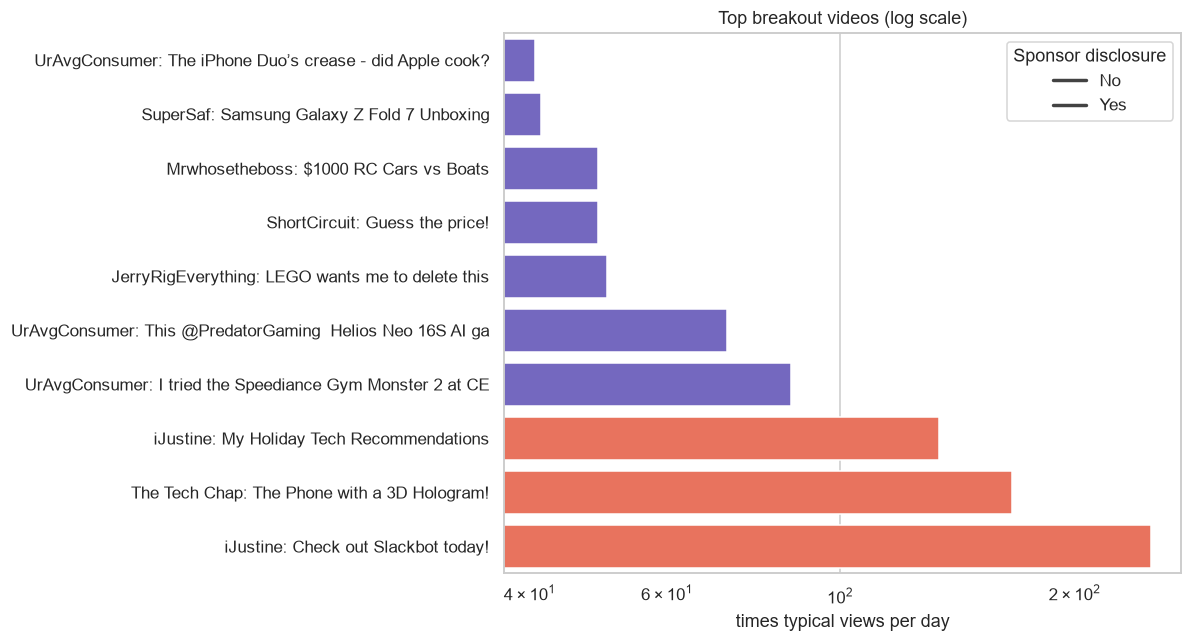

In [11]:
plot_breakouts = breakouts.head(10).copy().sort_values("performance_index")
plot_breakouts["label"] = plot_breakouts["channel_name"] + ": " + plot_breakouts["title"].str.slice(0, 42)
fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(data=plot_breakouts, y="label", x="performance_index", hue="is_sponsored", dodge=False, palette={0: "slateblue", 1: "tomato"}, ax=ax)
ax.set_xscale("log")
ax.set(title="Top breakout videos (log scale)", xlabel="times typical views per day", ylabel="")
ax.legend(title="Sponsor disclosure", labels=["No", "Yes"])
plt.tight_layout()
fig.savefig(FIGURES_DIR / "10_top_breakouts.png", dpi=140, bbox_inches="tight")
plt.show()

### Breakout finding

- `306 of 2,724` analyzed videos (`11.2%`) are at least `3x` typical.
- The top observed breakout is iJustine's **“Check out Slackbot today!”** at about `250x`; several other top breakouts are disclosed brand collaborations.
- Shorts have more extreme upside: about `17.6%` of non-sponsored Shorts are breakouts versus `6.6%` of non-sponsored long videos. Sponsored rows use a text heuristic, so do not read this as an ad-effect estimate.
- The top list is useful for investigation, not proof. A breakout can reflect a product launch, recommendation-system event, paid distribution, holiday timing, or an unusual creative concept.

**Conclusion:** channel-normalized outliers identify videos to study. They do not identify a single cause.

## Final conclusions and limitations

### Answers

1. **Upload day:** little association. Hour blocks show a possible midday/afternoon pattern, but channel scheduling confounds it.
2. **Video length:** no universal winner. `20+ min` videos have the highest fair median, while the within-channel Shorts/long result varies widely.
3. **Titles:** question marks, numbers and caps show little fair difference. Product topics, especially iPhone, show stronger association but also capture launch timing and demand.
4. **Engagement:** likes per view are similar across formats; comments per view are higher for long videos. Channel engagement profiles differ.
5. **Breakouts:** about one in nine analyzed videos is at least 3x its channel/format/age-group typical. Read the titles and sponsorship disclosures before interpreting them.

### Limits

- This is observational data. Every result is correlation, not causation.
- Only the newest 200 videos per channel were collected, and channels have different upload histories and format mixes.
- The `short` category means duration `<= 3 minutes`; the API does not provide a simple Shorts flag. YouTube changed Shorts view counting on March 31, 2025, so old and new Short counts may not be perfectly comparable.
- Subscriber counts are rounded by YouTube. Likes can be hidden; comments can be disabled.
- Sponsorship detection searches title and description text. It misses undisclosed deals and can flag a partner mention that did not cause paid distribution.
- API statistics are a snapshot and change over time. Refresh or delete stored statistics according to YouTube API policy before publishing a new snapshot.

Close the database connection before ending the notebook.

In [12]:
conn.close()